# Introduction

Online shopping has been popular in Armenia over recent years, and e-commerce websites are a very good source of information about products. One of such website is **MegaToys.am**, an Armenian online store selling numerous types of toys targeted at all age groups of children. Although the website contains rich product information like product names, prices, categories, and descriptions, this information does not come in a structured form. It would be hard for researchers, businesses, or consumers to analyze trends on toy pricing, product distribution, and category popularity.

The main problem is the lack of a ready-for-use dataset. In order to explore and analyze the toy market, it is necessary to collect, clean, and organize the data in structured format beforehand. This project resolves this issue by applying web scraping and data analysis techniques for the collection of product information from MegaToys.am.

The aim of this project is to fill this gap by providing a clean and organized dataset that can be used to explore market trends, generate visual insights, and support decision-making for businesses or researchers interested in the Armenian toy market.

# Data Collection

##  1. Data Scraping

**Objective**

The goal of this step is to collect product information from MegaToys.am in a structured format.

**The data includes**
* product Title - the name of the toy
* Brand - the manufacturer or brand
* Age - recommended age for the toy
* Price - listed price in Armenian Drams

**Tools Used**
* Python - programming language.
* Requests - to fetch website pages.
* BeautifulSoup - to parse HTML content.
* Pandas - to store the scraped data in a structured format.

Since the website lists products in paginated lists, we implement a loop that automatically increments the page offset to collect all available products until no more products are found.

We also included:
* Error handling to avoid crashes if there's some information missing about a product.
* Progress logging of how many products were scraped.
* CSV export to save data collected in a structured format for further steps.

This scraping process gives a clean dataset in CSV format that forms the basis for data cleaning and preprocessing.




### 1.1 Installing Essential Libraries

Install all necessary libraries. Some libraries (like pandas and bs4) are already available in Google Colab, but installing them again ensures compatibility and avoids version issues.

In [ ]:
!pip install requests -q
!pip install beautifulsoup4 -q
!pip install pandas -q

### 1.2 Importing Libraries
Import all required libraries for scraping the website, parsing HTML, storing data, and displaying tables in order to be able to use them.

In [ ]:
from bs4 import BeautifulSoup
import requests
import pandas as pd
from google.colab import files
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from collections import Counter
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, f_oneway
import re
import os

### 1.3 Importing Libraries
We define the base URL used for pagination and specify request headers.
The headers help the server treat our request like a real browser, preventing blocking and ensuring the page loads correctly.

In [ ]:
# Base URL for pagination (the last number will be added with offsets)
base_url = "https://megatoys.am/am/products/stream/0/0/"

# Headers to make the request look like it comes from a real browser
headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'
}

### 1.4 Defining the Scraping Function
Creating a reusable function that takes an offset value, loads the corresponding webpage, parses the HTML, and extracts product information.
The function handles missing fields safely with try/except block and returns structured data for each product as a list of dictionaries.

In [ ]:
def scrape_page(offset=0):
    # Build URL for a specific page based on offset
    url = f"{base_url}{offset}"

    # Send request to the page with browser-like headers
    response = requests.get(url, headers=headers)

    # Parse HTML content with BeautifulSoup
    soup = BeautifulSoup(response.content, "html.parser")

    # Find all products on the page
    products = soup.find_all("div", class_="product-list")

    data = []  # temporary container for extracted products

    # Loop through each product block
    for prod in products:

        # Extract product title
        try:
            title = prod.find("div", class_="product-list-title").find("a").text.strip()
        except:
            title = "N/A"

        # Extract brand (first products-age <p>)
        try:
            brand = prod.find_all("p", class_="products-age")[0].find("a").text.strip()
        except:
            brand = "N/A"

        # Extract recommended age (second products-age <p>)
        try:
            age = prod.find_all("p", class_="products-age")[1].text.strip()
        except:
            age = "N/A"

        # Extract price information
        try:
            price = prod.find("p", class_="product-price").text.strip()
        except:
            price = "N/A"

        # Append clean record to the dataset
        data.append({
            "Title": title,
            "Brand": brand,
            "Age": age,
            "Price": price
        })

    return data  # return list of dicts for the page

### 1.5 Creating a Folder and Defining the CSV File Path
This section creates a folder named data inside Google Colab and prepares the full file path of the CSV file.

In [ ]:
# Folder to save CSV in Colab
output_folder = "data"  # folder name
os.makedirs(output_folder, exist_ok=True)  # create folder if it doesn't exist
csv_path = os.path.join(output_folder, "megatoys_products.csv")  # full CSV path

### 1.6 Looping Through Offsets and Collect All Product Data
We create a loop that automatically visits every product page on the website. The script starts from offset 0 and increases the offset by 80 each time (because the website displays 80 products per page).

For each offset, the script
1. Calls scrape_page(offset) to extract all products from that page.
2. If the returned list is empty, it means there are no more products, so the loop stops.
3. If products are found, they are added to all_products, and a counter keeps track of how many items have been collected in total.
4. The offset is increased by 80, and the next page is scraped.

This loop continues until all available product data from the website has been scraped.

In [ ]:
offset = 0          # pagination offset (last number in URL)
all_products = []   # list to store all product dictionaries
product_counter = 0 # number of total products scraped

print("Starting scraping...")

# Loop through paginated pages
while True:
    # Scrape products from current offset
    page_data = scrape_page(offset)

    # Stop if no products found
    if not page_data:
        print("No more products found. Stopping.")
        break

    # Add scraped data to main list
    all_products.extend(page_data)

    # Update total product count
    product_counter += len(page_data)
    print(f"Offset {offset}: Total products scraped so far = {product_counter}")

    # Increment offset by 80 for next page
    offset += 80


Starting scraping...
Offset 0: Total products scraped so far = 80
Offset 80: Total products scraped so far = 160
Offset 160: Total products scraped so far = 240
Offset 240: Total products scraped so far = 320
Offset 320: Total products scraped so far = 400
Offset 400: Total products scraped so far = 480
Offset 480: Total products scraped so far = 560
Offset 560: Total products scraped so far = 640
Offset 640: Total products scraped so far = 720
Offset 720: Total products scraped so far = 800
Offset 800: Total products scraped so far = 880
Offset 880: Total products scraped so far = 960
Offset 960: Total products scraped so far = 1040
Offset 1040: Total products scraped so far = 1120
Offset 1120: Total products scraped so far = 1200
Offset 1200: Total products scraped so far = 1280
Offset 1280: Total products scraped so far = 1360
Offset 1360: Total products scraped so far = 1440
Offset 1440: Total products scraped so far = 1520
Offset 1520: Total products scraped so far = 1600
Offset 1

### 1.7 Creating DataFrame and Saving CSV
This block converts the scraped data into a structured Pandas DataFrame, adds product numbering, saves the data to a CSV file in the specified folder, and provides an option to download the CSV in Colab.

In [ ]:
# Convert the list of product dictionaries into a Pandas DataFrame
df = pd.DataFrame(all_products)

# Add indexing starting from 1
df.index += 1
df.index.name = "No."

# Save the full DataFrame to CSV in the "data" folder
df.to_csv(csv_path, index=True, encoding="utf-8-sig")
print(f"\nCSV file created successfully: {csv_path}")


# Download CSV directly in Colab
files.download(csv_path)


CSV file created successfully: data/megatoys_products.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 2. Data Cleaning
In this step, the scraped dataset was cleaned and standardized to make it suitable for analysis. Extra spaces were removed from the Title and Brand columns to ensure consistency. The Age column was processed by removing unwanted text such as “Տարիքը” and “+”, converting month-based ages (e.g., “10 ամս.”) into years by dividing by 12, and transforming all age values into a numeric float format. Missing age values were handled by replacing them with 0 to avoid errors in further analysis.

The Price column was also cleaned by removing words and symbols such as “Գինը” and “Դր.”, leaving only numeric values. All cleaned values were converted into numeric formats to allow accurate statistical analysis and visualization in later steps.

### 2.1 Loading the Scraped Dataset
In this step, we load the CSV file created during the data scraping phase and create a copy of the dataset to safely perform data cleaning operations without modifying the original data.

In [ ]:
# Path of CSV from scraping step
input_path = "data/megatoys_products.csv"

# Read the CSV file
df = pd.read_csv(input_path)

# Make a copy of the dataframe
clean_df = df.copy()

### 2.2 Cleaning Text Columns (Title and Brand)
This step removes unnecessary spaces from the Title and Brand columns to ensure the text data is consistent and ready for analysis.

In [ ]:
clean_df["Title"] = clean_df["Title"].astype(str).str.strip() # Cleaning title
clean_df["Brand"] = clean_df["Brand"].astype(str).str.strip() # Cleaning Brand

### 2.3 Cleaning the Age Column
This step standardizes the Age column by handling missing values, converting months to years, removing extra symbols, and transforming all values into numeric format.

In [ ]:
# Convert the Age column to string type to allow text operations
clean_df["Age"] = clean_df["Age"].astype(str)

# Handle missing age values:
# If the cell contains only "Տարիքը" or is empty, replace it with "0"
clean_df.loc[
    (clean_df["Age"].str.strip() == "Տարիքը") |
    (clean_df["Age"].str.strip() == ""),
    "Age"
] = "0"

# Create a mask for rows that contain "ամս" (months)
# These values will be converted into years
month_mask = clean_df["Age"].str.contains("ամս", na=False)

# Convert ages written in months to years (divide by 12)
clean_df.loc[month_mask, "Age"] = (
    clean_df.loc[month_mask, "Age"]
    .str.extract(r"(\d+\.?\d*)", expand=False)   # extract numeric part
    .astype(float) / 12                         # convert months to years
)

# Process normal age values written in years (with + or decimals)
clean_df.loc[~month_mask, "Age"] = (
    clean_df.loc[~month_mask, "Age"]
    .str.replace("Տարիքը", "", regex=False)     # remove "Տարիքը" label
    .str.replace("+", "", regex=False)           # remove + sign
    .str.extract(r"(\d+\.?\d*)", expand=False)   # extract numeric part
)

# Convert the entire Age column to float
clean_df["Age"] = pd.to_numeric(clean_df["Age"], errors="coerce").fillna(0.0) # Invalid or empty values become 0.0

### 2.4 Cleaning the Price Column
In this step, we clean the Price column by removing text labels ("Գինը") and extracting only the numeric values. Missing or invalid prices are converted to 0.0 to keep the dataset consistent for analysis.

In [ ]:
# Convert the Price column to string to safely apply text operations
clean_df["Price"] = (
    clean_df["Price"]
    .astype(str)

    # Remove Armenian word for "Price"
    .str.replace("Գինը", "", regex=False)

    # Remove Armenian currency symbol (AMD)
    .str.replace("Դր.", "", regex=False)

    # Remove newline characters
    .str.replace("\n", "", regex=False)

    # Extract only numeric values (including decimals)
    .str.extract(r"(\d+\.?\d*)", expand=False)
)

# Convert cleaned Price values to float type
# If a value is missing or invalid, replace with 0.0
clean_df["Price"] = pd.to_numeric(clean_df["Price"], errors="coerce").fillna(0.0)

### 2.5 Save Cleaned CSV
This block saves the cleaned dataset as a new CSV file in the Colab environment.

In [ ]:
# Define output file path for cleaned data
output_path = "data/megatoys_products_cleaned.csv"

# Save the cleaned DataFrame to CSV
clean_df.to_csv(output_path, index=False, encoding="utf-8-sig")

# Print confirmation
print("Cleaned CSV created:", output_path)


Cleaned CSV created: data/megatoys_products_cleaned.csv


### 2.6 Download CSV File
This block allows you to download the cleaned CSV file directly from Google Colab to your local computer.


In [ ]:
# Download the cleaned CSV file
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Preprocessing

## 3. Data Preprocessing
In this step, the cleaned dataset was further prepared for analysis by creating new features, transforming numerical values, and converting categorical data into numerical formats. This made the dataset more structured and suitable for deeper analysis.

We performed the following tasks:
* Creating new analytical features from existing columns.
* Normalising numerical values for consistent scaling.
* Converting categorical text data into numerical form.
* Applying text processing to product titles.
* Optimaizing dataset structure.

### 3.1 Loading Cleaned Dataset
Load the cleaned dataset from the previous step and copy to preserve the original data.

In [ ]:
# Load cleaned CSV file
input_path = "data/megatoys_products_cleaned.csv"
df = pd.read_csv(input_path)

# Create a reserve copy
pre_df = df.copy()

### 3.2 Feature Engineering
Create new features to enhance analysis:
1.   A price category feature (Low, Medium, High).
2.   A baby toy indicator showing whether a toy is suitable for children under 3 years old.

In [ ]:
# Create Price Category feature
def price_category(price):
    if price < 5000:
        return "Low"
    elif price < 15000:
        return "Medium"
    else:
        return "High"

pre_df["Price_Category"] = pre_df["Price"].apply(price_category)

# Create Baby Toy flag (True/False)
pre_df["Is_Baby_Toy"] = pre_df["Age"].apply(lambda x: True if x < 3 else False)

### 3.3 Data Transformation (Normalization)
Normalizing numerical values such as Age and Price using Min-Max scaling to bring them into a common range.

In [ ]:
# Create a MinMaxScaler object
scaler = MinMaxScaler()

# Apply normalization to the "Age" and "Price" columns
# The original values are transformed into a new scale (0 to 1) and stored in new columns: "Age_Norm" and "Price_Norm"
pre_df[["Age_Norm", "Price_Norm"]] = scaler.fit_transform(pre_df[["Age", "Price"]])


### 3.4 Data Encoding
Text-based categorical data is converted into numerical values using Label Encoding for brands and One-hot Encoding for price categories

In [ ]:
# Create a LabelEncoder object
le = LabelEncoder()
# Convert Brand names into numeric values
pre_df["Brand_Encoded"] = le.fit_transform(pre_df["Brand"])

# Create one-hot encoded columns for Price_Category
price_dummies = pd.get_dummies(pre_df["Price_Category"], prefix="Price")

# Add the new one-hot encoded columns to the main DataFrame
pre_df = pd.concat([pre_df, price_dummies], axis=1)

### 3.5 Text Preprocessing
Cleaning product titles and tokenizing in order to prepare text data for further analysis.

In [ ]:
# Function to clean and tokenize text
def clean_text(text):
    text = text.lower()

    # Remove special characters (keep only letters and numbers)
    text = re.sub(r"[^a-zա-ֆ0-9 ]", "", text)

    # Split the sentence into individual words (tokens)
    words = text.split()

    return words

# Apply the cleaning function to the Title column
# Creating a new column containing lists of words for each product title
pre_df["Title_Tokens"] = pre_df["Title"].apply(clean_text)

### 3.6 Handling Imbalanced Data
Checking and printing class distributions to understand data imbalance in categories.

In [ ]:
print("Price Category Distribution:")
print(Counter(pre_df["Price_Category"]))

Price Category Distribution:
Counter({'High': 772, 'Medium': 522, 'Low': 330})


### 3.7 Feature Selection
Keeping only the most relevant columns to improve dataset clarity and ease to analyze.

In [ ]:
pre_df = pre_df[[
    "Title", "Brand", "Age", "Price",
    "Price_Category", "Is_Baby_Toy",
    "Age_Norm", "Price_Norm",
    "Brand_Encoded",
    "Price_Low", "Price_Medium", "Price_High"
]]

### 3.8 Saving Preprocessed Dataset
Saving the final preprocessed dataset as a new CSV file.

In [ ]:
# Set the output file path
output_path = "data/megatoys_products_preprocessed.csv"

# Save the DataFrame to a CSV file
pre_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Preprocessed CSV saved at:", output_path)


Preprocessed CSV saved at: data/megatoys_products_preprocessed.csv


### 3.9 Downloading the Dataset

Downloading the file to the local machine from Google Colab.

In [ ]:
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Analysis

## 4. Data Analysis (Exploratory Data Analysis (EDA))

### 4.1 Descriptive statistics
In this step, we explored the basic characteristics of the dataset to better understand the toy products collected from MegaToys.am. We used different statistical functions to examine how the data is structured and how the values are distributed.

Here we applied:

* df.info() to quickly check the structure of the dataset, including column names, data types, and missing values.
* df.describe() to generate a summary of the numerical columns, showing key statistics such as count, mean, minimum, maximum, and standard deviation.
* Statistical functions like mean, median, mode, and standard deviation to understand the central values and variability of prices and ages.

####4.1.1 Computing summary statistics such as mean, median, mode, and standard deviation for numerical features.


In [ ]:
# Load the preprocessed dataset created in the previous step
input_path = "data/megatoys_products_preprocessed.csv"
df = pd.read_csv(input_path)

# Display general structure of the dataset
print("Dataset Info:")
df.info()

# General descriptive statistics (count, mean, std, min, max, etc.)
print("\nDescriptive Statistics:")
df.describe()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1624 entries, 0 to 1623
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Title           1624 non-null   object 
 1   Brand           1624 non-null   object 
 2   Age             1624 non-null   float64
 3   Price           1624 non-null   int64  
 4   Price_Category  1624 non-null   object 
 5   Is_Baby_Toy     1624 non-null   bool   
 6   Age_Norm        1624 non-null   float64
 7   Price_Norm      1624 non-null   float64
 8   Brand_Encoded   1624 non-null   int64  
 9   Price_Low       1624 non-null   bool   
 10  Price_Medium    1624 non-null   bool   
 11  Price_High      1624 non-null   bool   
dtypes: bool(4), float64(3), int64(2), object(3)
memory usage: 108.0+ KB

Descriptive Statistics:


,Age,Price,Age_Norm,Price_Norm,Brand_Encoded
count,1624.000000,1624.000000,1624.000000,1624.000000,1624.000000
mean,4.217775,23960.314039,0.234321,0.039359,62.134852
std,3.052702,35449.494718,0.169595,0.059221,29.388169
min,0.000000,400.000000,0.000000,0.000000,0.000000
25%,3.000000,5900.000000,0.166667,0.009188,44.750000
50%,3.000000,14900.000000,0.166667,0.024223,64.000000
75%,6.000000,28900.000000,0.333333,0.047611,91.000000
max,18.000000,599000.000000,1.000000,1.000000,106.000000


In [ ]:
# Calculate the average (mean) values of numerical columns
print("\nMean values:")
print(df[["Age", "Price", "Age_Norm", "Price_Norm"]].mean(), "\n")

# Calculate the median values of numerical columns
print("\nMedian values:")
print(df[["Age", "Price", "Age_Norm", "Price_Norm"]].median(), "\n")

# Calculate the most frequent values (mode) in numerical columns
print("\nMode values:")
print(df[["Age", "Price"]].mode(), "\n")

# Calculate standard deviation to understand data spread
print("\nStandard Deviation:")
print(df[["Age", "Price", "Age_Norm", "Price_Norm"]].std(), "\n")


Mean values:
Age               4.217775
Price         23960.314039
Age_Norm          0.234321
Price_Norm        0.039359
dtype: float64 


Median values:
Age               3.000000
Price         14900.000000
Age_Norm          0.166667
Price_Norm        0.024223
dtype: float64 


Mode values:
   Age  Price
0  3.0   4900 


Standard Deviation:
Age               3.052702
Price         35449.494718
Age_Norm          0.169595
Price_Norm        0.059221
dtype: float64 



#### 4.1.2 Examining the distribution of data to identify central tendencies and variations.

In [ ]:
# Calculate variance to measure data dispersion
print("\nVariance:")
print(df[["Age", "Price"]].var(), "\n")

# Calculate range to understand spread of values
price_diff = df["Price"].max() - df["Price"].min()
print(f"Range of Price: {df["Price"].min()} - {df["Price"].max()}")
print("Price Difference:", price_diff)


Variance:
Age      9.318987e+00
Price    1.256667e+09
dtype: float64 

Range of Price: 400 - 599000
Price Difference: 598600


### 4.2 Distribution Analysis
In this step, we visualize the distribution of numerical variables to better understand their spread, shape, and potential anomalies. We use histograms and box plots to detect skewness, outliers, and patterns that indicate whether the data follows a normal distribution. We also calculate skewness and kurtosis to quantify the shape of the distributions.

#### 4.2.1 Visualizing the distribution of key variables using histograms, box plots and bar graph.

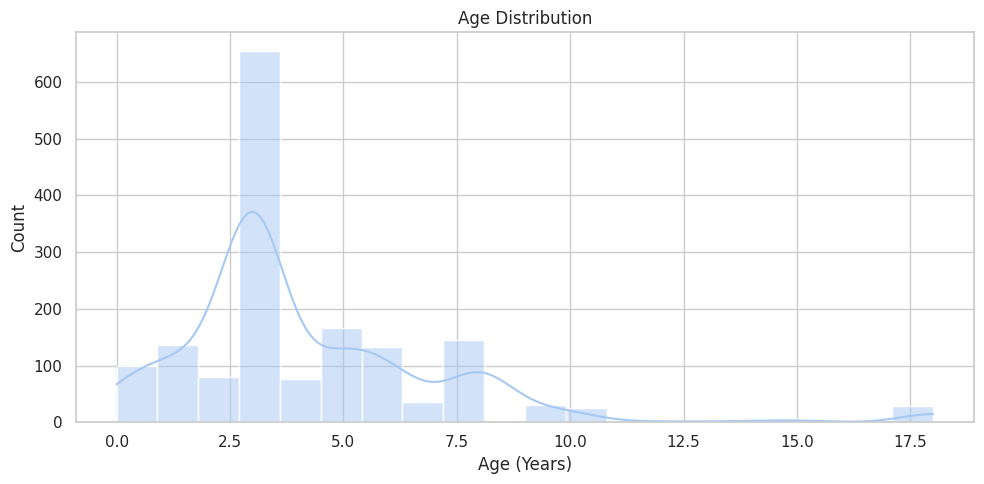

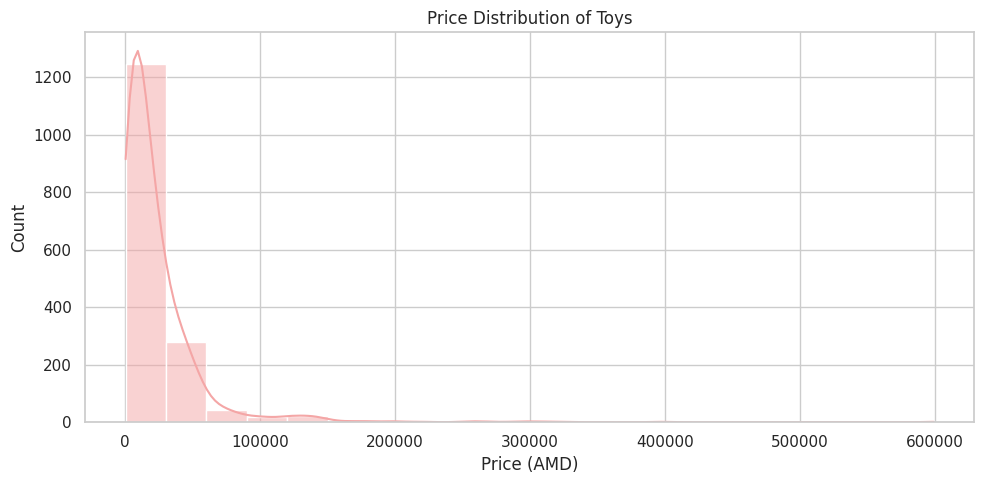

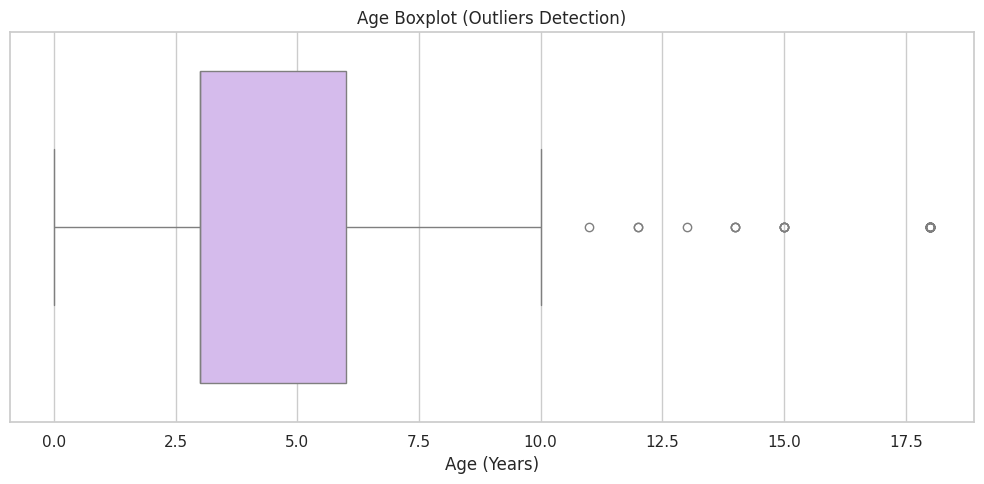

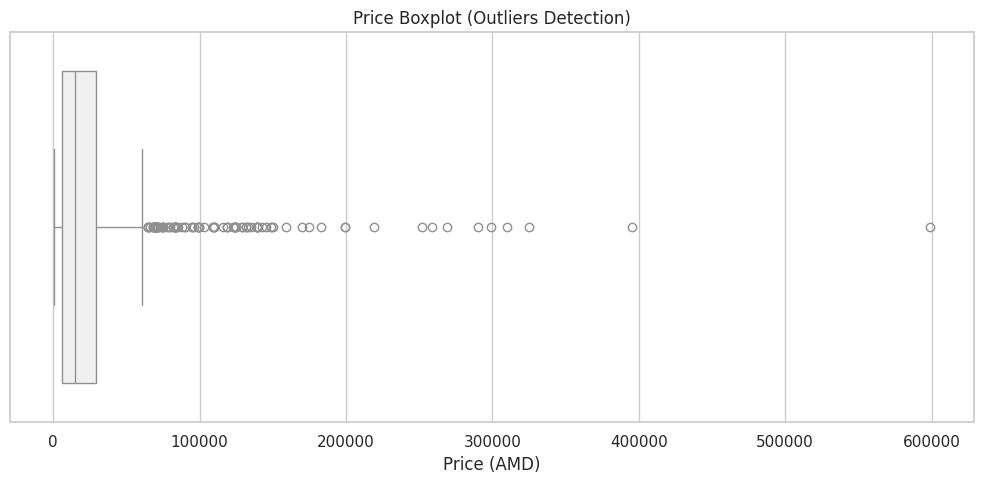

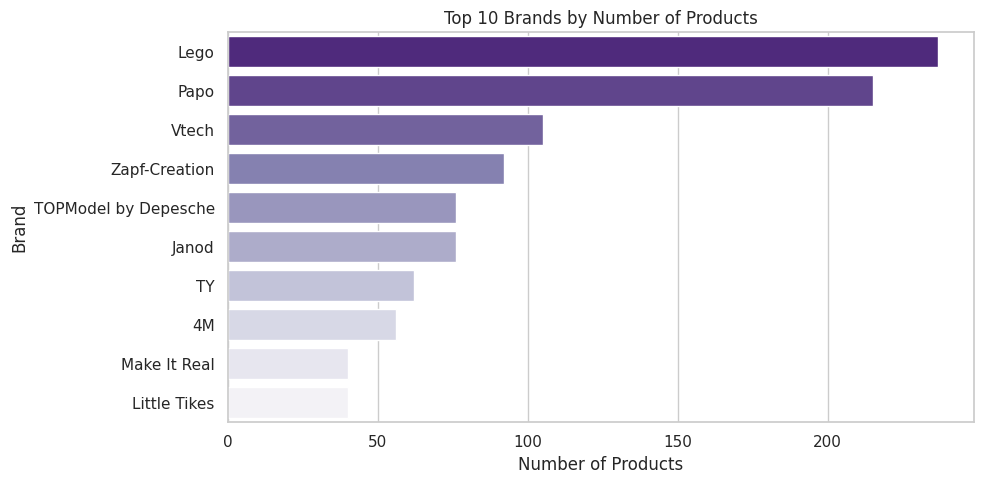

In [ ]:
# 0. SET THE STYLE
# Apply a clean, white grid background style
sns.set_theme(style="whitegrid")

# Define custom pastel color palette
pastel_pink = "#f4a6a6"
pastel_blue = "#a6c8f4"
pastel_purple = "#d6b3f4"
pastel_linen = "#F0F0F0"

# Set a figure size for all plots
FIG_SIZE = (10, 5)
FIG_DPI = 100



# 1. AGE DISTRIBUTION PLOT
# Create histogram with KDE line for Age
plt.figure(figsize=FIG_SIZE, dpi=FIG_DPI)
sns.histplot(df["Age"], bins=20, kde=True, color=pastel_blue)

# Add titles and axis labels
plt.title("Age Distribution")
plt.xlabel("Age (Years)")
plt.ylabel("Count")

# Adjust layout and display the plot
plt.tight_layout()
plt.show()



# 2. PRICE DISTRIBUTION PLOT
# Create histogram with KDE line for Price
plt.figure(figsize=FIG_SIZE, dpi=FIG_DPI)
sns.histplot(df["Price"], bins=20, kde=True, color=pastel_pink)

# Add titles and labels
plt.title("Price Distribution of Toys")
plt.xlabel("Price (AMD)")
plt.ylabel("Count")

# Adjust layout and display the plot
plt.tight_layout()
plt.show()



# 3. AGE BOXPLOT
# Create boxplot to detect outliers in Age
plt.figure(figsize=FIG_SIZE, dpi=FIG_DPI)
sns.boxplot(x=df["Age"], color=pastel_purple)

# Add title and labels
plt.title("Age Boxplot (Outliers Detection)")
plt.xlabel("Age (Years)")

# Show plot
plt.tight_layout()
plt.show()



# 4. PRICE BOXPLOT
# Create boxplot to detect outliers in Price
plt.figure(figsize=FIG_SIZE, dpi=FIG_DPI)
sns.boxplot(x=df["Price"], color=pastel_linen)

# Add title and labels
plt.title("Price Boxplot (Outliers Detection)")
plt.xlabel("Price (AMD)")

# Show plot
plt.tight_layout()
plt.show()



# 5. TOP 10 BRANDS BAR CHART
# Get top 10 brands by product count
top_brands = df["Brand"].value_counts().head(10)

# Reverse the "Purples" color palette for visual effect
reversed_palette = sns.color_palette("Purples", n_colors=len(top_brands))[::-1]

# Create the horizontal bar chart
plt.figure(figsize=FIG_SIZE, dpi=FIG_DPI)
sns.barplot(
    x=top_brands.values,
    y=top_brands.index,
    hue=top_brands.index,
    palette=reversed_palette,
    legend=False
)

# Add title and labels
plt.title("Top 10 Brands by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Brand")

# Display the plot
plt.tight_layout()
plt.show()

#### 4.2.2 Identifing skewness, kurtosis, or any patterns indicative of non-normality.

In [ ]:
# 6. SKEWNESS ANALYSIS
# Skewness shows the asymmetry of the distribution
# Positive value → right-skewed
# Negative value → left-skewed
age_skew = df["Age"].skew()
price_skew = df["Price"].skew()
print("\nSkewness of Age:", age_skew)
print("Skewness of Price:", price_skew)



# 7. KURTOSIS ANALYSIS
# Kurtosis shows how heavy the tails of the distribution are
# High value → more outliers (heavy tails)
age_kurt = df["Age"].kurtosis()
price_kurt = df["Price"].kurtosis()
print("\nKurtosis of Age:", age_kurt)
print("Kurtosis of Price:", price_kurt)



# 8. INTERPRETATIONS
if abs(age_skew) < 0.5:
    print("\nAge distribution of age is approximately symmetrical.")
else:
    print("\nAge distribution of age is skewed.")

if abs(price_skew) < 0.5:
    print("Price distribution of price is approximately symmetrical.")
else:
    print("Price distribution of price is skewed.")



Skewness of Age: 1.940976179285121
Skewness of Price: 6.2091065266323655

Kurtosis of Age: 5.831626449083702
Kurtosis of Price: 64.95537544216242

Age distribution of age is skewed.
Price distribution of price is skewed.


### 4.3 Correlation Analysis
In this step, we analyzed the relationships between numerical variables in the dataset, such as Age, Price, and encoded Brand values. A correlation matrix and heatmap are used to visualize how strongly these variables are related. This helps identify patterns, dependencies, and possible multicollinearity between features.

#### 4.3.1 Exploring pairwise correlations between numerical features using correlation matrices.


In [ ]:
# Select only necessary numeric columns for correlation
corr_df = df[["Age", "Price", "Brand_Encoded"]]


# CORRELATION MATRIX
# Calculate correlation matrix
correlation_matrix = corr_df.corr()

# Print the correlation values
print("Correlation Matrix:")
print(correlation_matrix, '\n')

Correlation Matrix:
                    Age     Price  Brand_Encoded
Age            1.000000  0.094128      -0.202420
Price          0.094128  1.000000      -0.083123
Brand_Encoded -0.202420 -0.083123       1.000000 



#### 4.3.2 Visualizing correlations using heatmap to identify strong relationships and potential multicollinearity.

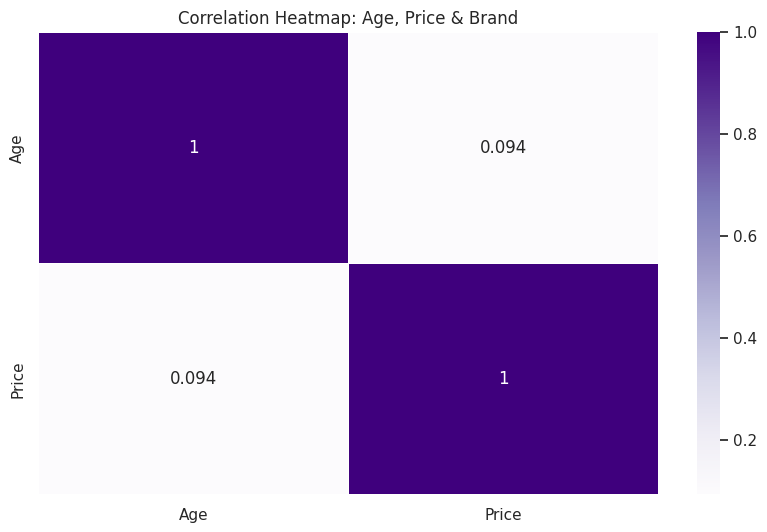

In [ ]:
# HEATMAP VISUALIZATION
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,        # show correlation values
    cmap="Purples",
    linewidths=0.5
)

# Show the plot
plt.title("Correlation Heatmap: Age, Price & Brand")
plt.show()

### 4.4 Hypothesis Testing
In this section, we test statistical hypotheses to verify whether certain patterns observed in the data are statistically significant. We use a t-test for comparing two groups and ANOVA for comparing multiple groups. We tested two statistical hypotheses to understand pricing patterns in the toy dataset. These tests help validate whether observed price differences are statistically meaningful rather than random.

#### 4.4.1 Formulating hypotheses based on initial observations.
**Hypothesis 1** examines whether there is a significant difference in the average price between baby toys and non-baby toys using a t-test.
* H₀ (Null Hypothesis): There is no difference in average prices between baby toys and non-baby toys.
* H₁ (Alternative Hypothesis): There is a significant difference in average prices.

**Hypothesis 2** analyzes whether the most popular brand has a different average price compared to all other brands combined using ANOVA.
* H₀ (Null Hypothesis): The average price of toys is the same for the most popular brand and other brands
* H₁ (Alternative Hypothesis): The average price of toys differs between the most popular brand and other brands

#### 4.4.2 Using statistical tests (t-tests, ANOVA, etc.) to validate or reject hypotheses.

##### 4.4.2.1 HYPOTHESIS 1 (T-TEST)
H0: There is no difference in average prices between baby toys and non-baby toys

H1: There is significant difference in average prices between baby toys and non-baby toys

In [ ]:
# Load preprocessed dataset
df = pd.read_csv("data/megatoys_products_preprocessed.csv")

# Separate prices by group
baby_toys = df[df["Is_Baby_Toy"] == True]["Price"]
non_baby_toys = df[df["Is_Baby_Toy"] == False]["Price"]

# Perform independent T-test
t_stat, p_value = ttest_ind(baby_toys, non_baby_toys, equal_var=False)

# Print results
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("We FAIL TO REJECT H0")
    print("Conclusion: There IS NO significant difference in average prices between baby and non-baby toys.")
else:
    print("We REJECT H0")
    print("Conclusion: There is significant difference in average prices between baby and non-baby toys.")


T-statistic: 4.287227228755497
P-value: 2.274834231434409e-05
We FAIL TO REJECT H0
Conclusion: There IS NO significant difference in average prices between baby and non-baby toys.


##### 4.4.2.2 HYPOTHESIS 2 – ANOVA
H0: The average price of toys is the same for the most popular brand and other brands

H1: The average price of toys differs between the most popular brand and other brands

In [ ]:

# Find the most common brand
top_brand = df["Brand"].mode()[0]

# Create two groups
top_brand_prices = df[df["Brand"] == top_brand]["Price"]
other_brand_prices = df[df["Brand"] != top_brand]["Price"]

# Run ANOVA test
anova_stat, anova_p = f_oneway(top_brand_prices, other_brand_prices)

print("\nHypothesis 2 (ANOVA) Results:")
print("Most common brand:", top_brand)
print("F-statistic:", anova_stat)
print("P-value:", anova_p)

# Interpretation
if anova_p < 0.05:
    print("Reject H0: Significant difference between brands.")
else:
    print("Fail to reject H0: No significant difference between brands.")



Hypothesis 2 (ANOVA) Results:
Most common brand: Lego
F-statistic: 18.04126245795143
P-value: 2.2844180898574976e-05
Reject H0: Significant difference between brands.


## 5. Data Visualization

### 5.1 Scatter Plots
In this step, scatter plots are used to visually explore the relationships between different numerical and encoded features in the dataset. These visualizations help identify patterns, clusters, and trends such as how price relates to age, how brands differ in pricing, and whether certain price categories are associated with specific age groups.
As results we see that:
1. **Age vs Price:** Older age-targeted toys tend to have higher prices, with a few expensive outliers.
2. **Age vs Encoded Brand:** Different brands are spread across age groups, but some brands appear more frequently for certain age ranges.
3. **Price vs Encoded Brand:** Some brands clearly focus on higher-priced products, while others cluster in the budget range.
4. **Age vs Price Category (Encoded):** Higher price categories appear more often in toys designed for older children.

#### 5.1.1 Creating the Scatter Plots
This part uses scatter plots to explore relationships and patterns between age, price, and brand variables.

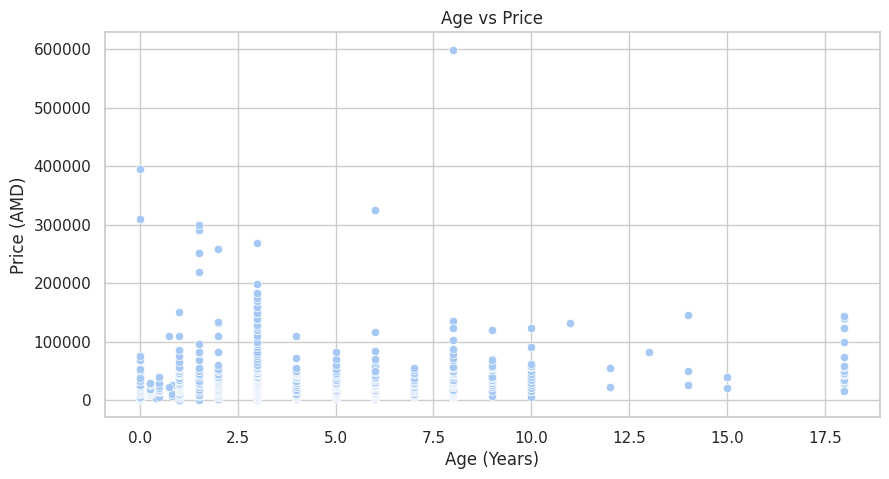

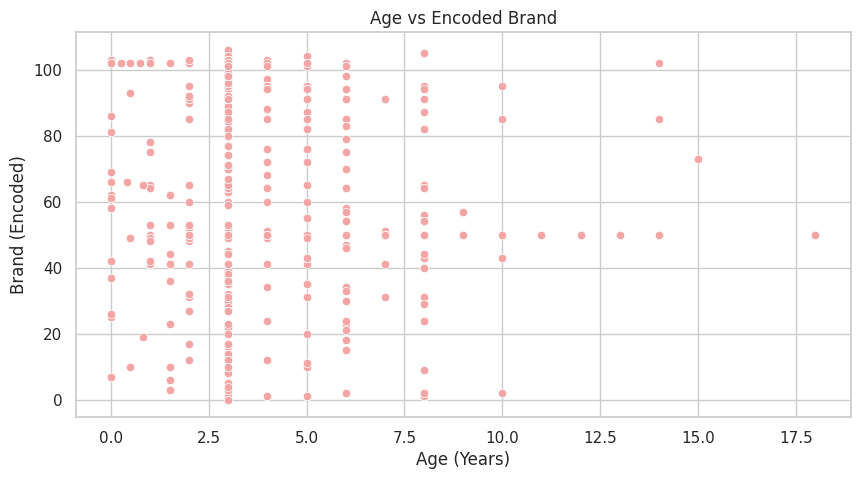

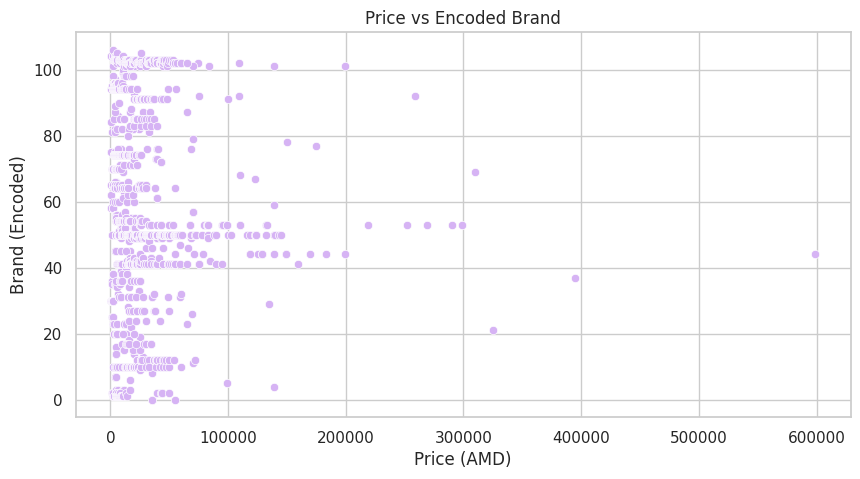

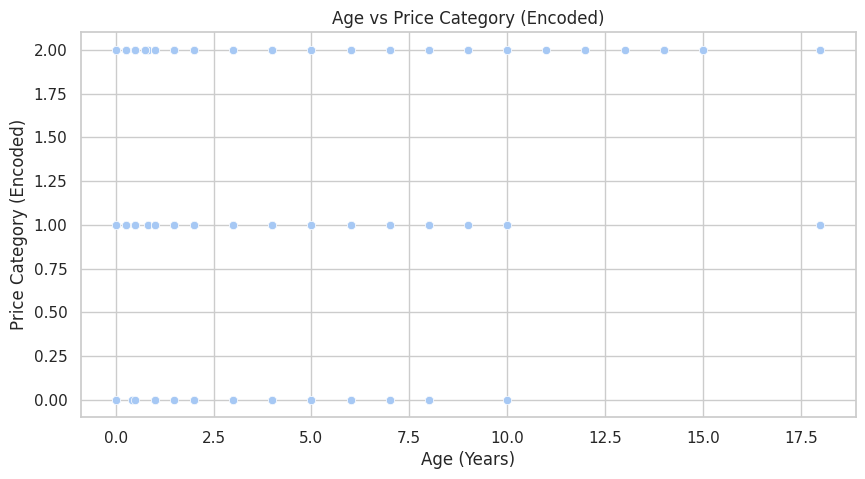

In [ ]:
# Set a consistent figure size for all scatter plots
FIG_SIZE = (10, 5)



# 1. AGE vs PRICE
# This scatter plot shows how product prices change with age categories.
plt.figure(figsize=FIG_SIZE)
sns.scatterplot(x="Age", y="Price", data=df, color=pastel_blue)
plt.title("Age vs Price")
plt.xlabel("Age (Years)")
plt.ylabel("Price (AMD)")
plt.show()



# 2. AGE vs BRAND (ENCODED)
# This plot shows the relationship between age and brand (encoded numerically).
plt.figure(figsize=FIG_SIZE)
sns.scatterplot(x="Age", y="Brand_Encoded", data=df, color=pastel_pink)
plt.title("Age vs Encoded Brand")
plt.xlabel("Age (Years)")
plt.ylabel("Brand (Encoded)")
plt.show()



# 3. PRICE vs BRAND (ENCODED)
# This plot shows how product prices vary by brand.
plt.figure(figsize=FIG_SIZE)
sns.scatterplot(x="Price", y="Brand_Encoded", data=df, color=pastel_purple)
plt.title("Price vs Encoded Brand")
plt.xlabel("Price (AMD)")
plt.ylabel("Brand (Encoded)")
plt.show()


3

# 4. AGE vs PRICE CATEGORY (ENCODED)
# Converting Price_Category to numeric values
df["Price_Category_Encoded"] = df["Price_Category"].map({
    "Low": 0,
    "Medium": 1,
    "High": 2
})
# This scatter plot shows how age relates to pricing categories.
plt.figure(figsize=FIG_SIZE)
sns.scatterplot(x="Age", y="Price_Category_Encoded", data=df, color=pastel_blue)
plt.title("Age vs Price Category (Encoded)")
plt.xlabel("Age (Years)")
plt.ylabel("Price Category (Encoded)")
plt.show()

#### 5.1.2 Results of Scatter Plot Analysis

**Age vs Price**

The scatter plot shows that toy prices do not increase consistently with age. Most products for different ages are concentrated in the lower price range, while a few very expensive toys appear as outliers.
This indicates that
* Price is not strongly dependent on the target age.
* There are some premium products for certain ages.


**Age vs Brand**

This plot shows a wide spread of brands across all age groups. There is no strong visible clustering that would suggest that specific brands target only certain ages.

We observe that:

* Many brands produce toys for multiple age groups.
* Both baby-targeted and older-kid brands are distributed across the age range.


**Price vs Encoded Brand**

This visualization shows clear price clustering by brand.

We can identify:

* Some brands mostly fall in the lower price range → budget brands.
* Some brands have higher price → premium brands.
* A few brands produce very expensive products, visible as strong outliers.


**Age vs Price Category**

This plot uses price categories (Low, Medium, High) and compares them with age.

The results show that:

* Low and Medium-priced toys are common across almost all ages.
* High-priced toys are more scattered and less frequent.
* There is no strict dependency between age and price category.


**Summary**

Overall, the scatter plot analysis shows that:

* Price is weakly related to age.
* Brand has a stronger influence on price than age.
* Some brands act as premium brands, while others are more affordable.
* Age does not strongly determine the price category.

### 5.2 Histograms and Density Plots
In this section, histograms and density plots are used to visualize how numerical values are distributed in the dataset. These plots help to understand the frequency, spread, and overall shape of the data, making it easier to detect patterns, extreme values, and irregular distributions.

#### 5.2.1 Visualizing the distribution of numerical variables to understand their frequency and spread
This step focuses on visualizing how often different values appear in the dataset. Histograms show the frequency of values in bins, while density (KDE) curves display the smooth distribution of the data. These visualizations help to understand how concentrated or spread out the values of Age and Price are.

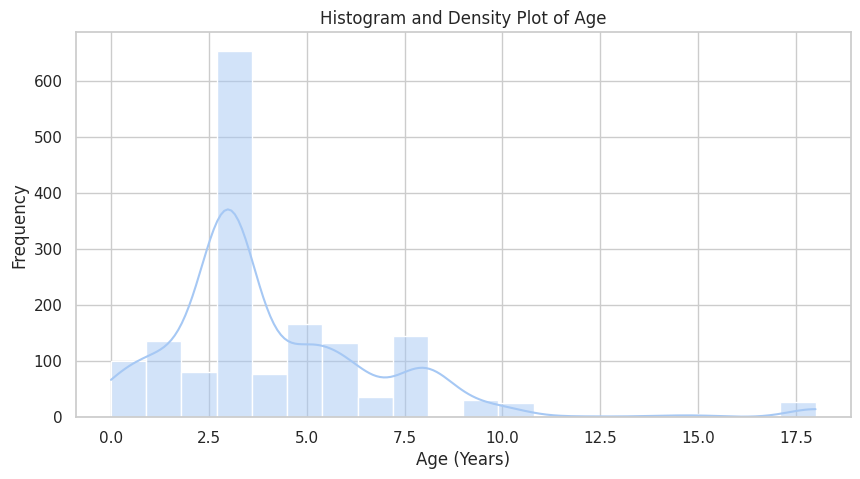

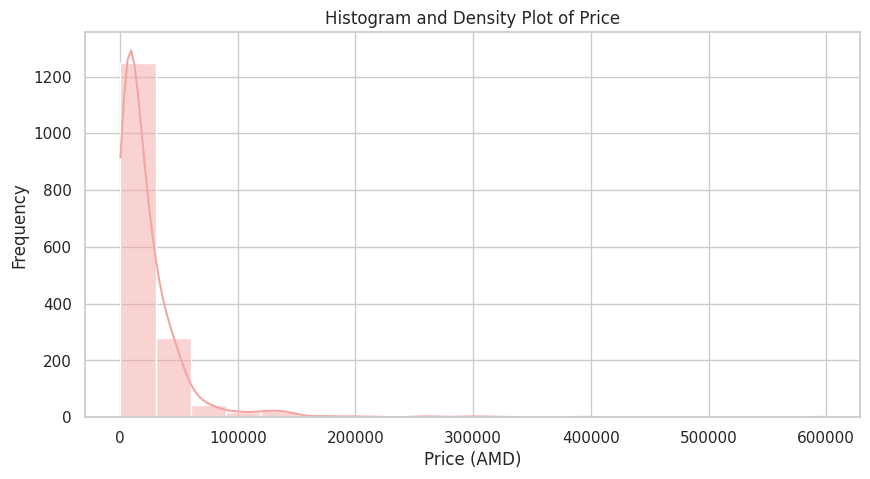

In [ ]:
# 1. Age Histogram with Density Curve
plt.figure(figsize=FIG_SIZE)
sns.histplot(df["Age"], bins=20, kde=True, color=pastel_blue)
plt.title("Histogram and Density Plot of Age")
plt.xlabel("Age (Years)")
plt.ylabel("Frequency")
plt.show()

# 2. Price Histogram with Density Curve
plt.figure(figsize=FIG_SIZE)
sns.histplot(df["Price"], bins=20, kde=True, color=pastel_pink)
plt.title("Histogram and Density Plot of Price")
plt.xlabel("Price (AMD)")
plt.ylabel("Frequency")
plt.show()


#### 5.2.2 Identifing potential outliers and understand the shape of the data

From the histograms and density plots, we can observe that most values are concentrated in lower ranges, while a small number of products have very large values that act as outliers. The distributions show visible skewness, indicating that the data is not perfectly normally distributed. These patterns suggest that extreme values exist and the dataset contains uneven distributions.

### 5.3 Heat Maps
In this part, heat maps are used to visually represent the correlation between numerical variables. A color-coded matrix helps quickly identify strong and weak relationships, as well as positive and negative correlations between features.

#### 5.3.1 Creating the Scatter Plots
This step computes a correlation matrix for selected numerical variables and visualizes it using a heat map. The color intensity shows how strongly variables are related.

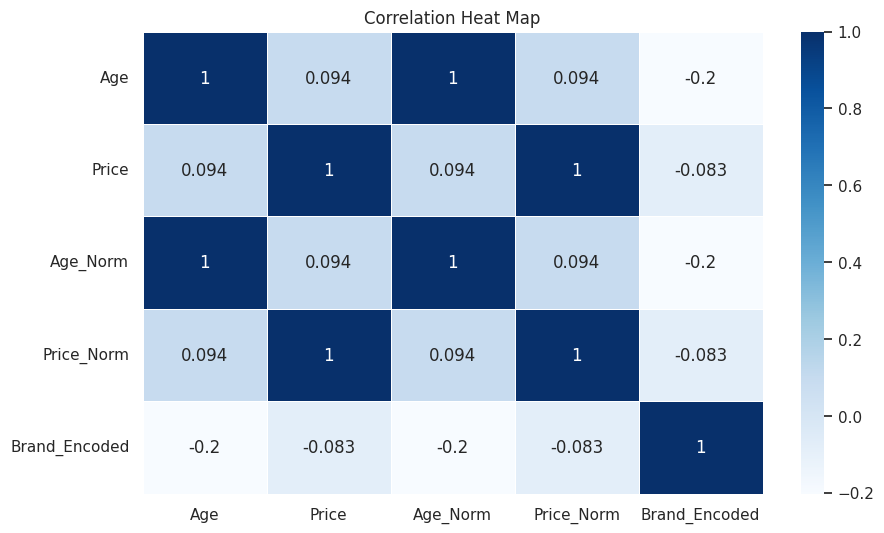

In [ ]:
# HEAT MAP: CORRELATION MATRIX

# Select only numerical columns for correlation
numeric_cols = df[["Age", "Price", "Age_Norm", "Price_Norm", "Brand_Encoded"]]

# Calculate the correlation matrix
corr_matrix = numeric_cols.corr()

# Create a new figure for the heatmap
plt.figure(figsize=(10, 6))

# Draw the heatmap using seaborn
sns.heatmap(
    corr_matrix,
    annot=True,            # Show correlation values inside the cells
    cmap="Blues",
    linewidths=0.5,        # Add space between cells
    linecolor="white"      # White grid lines for better readability
)

# Add a title
plt.title("Correlation Heat Map")

# Display the heatmap
plt.show()

#### 5.3.2 Results of Heat Map

The heat map shows that:

* Age and Price have a weak correlation, meaning price does not strongly depend on age.
* Normalized and original values have strong correlations, which confirms correct transformations.
* Brand (Encoded) and Price show moderate correlation, indicating that brand influences pricing more than age.

### 5.4 Bar Plots
This section visualizes categorical data using bar plots to show how frequently each category appears in the dataset. It helps compare different brands and price categories by displaying product counts in a clear and visual way. Bar plots make it easy to identify dominant categories and patterns in the data.

#### 5.4.1 Generating bar plots to represent the distribution of categorical variables.

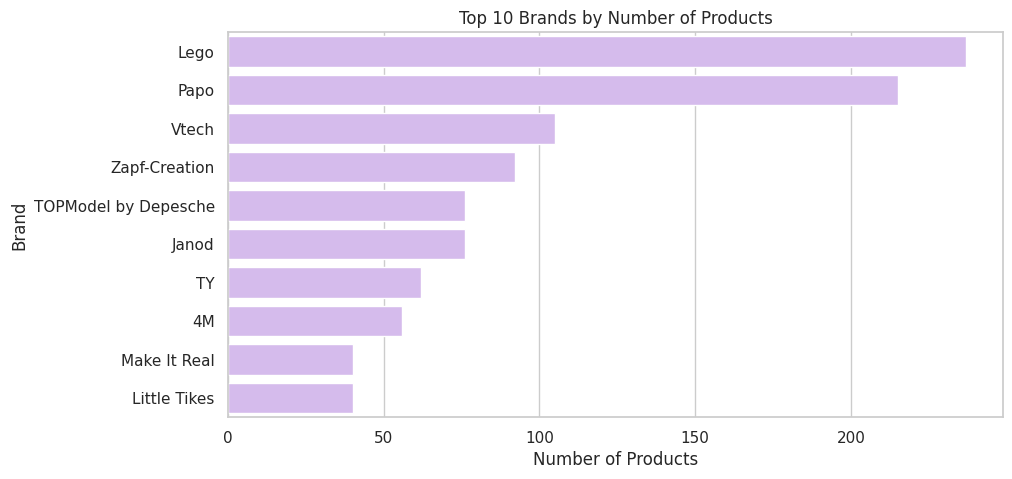

In [ ]:
# 1. TOP 10 BRANDS BY PRODUCT COUNT
# Count how many products belong to each brand
# Then select only the top 10 most frequent brands
top_brands = df["Brand"].value_counts().head(10)

# Create a new figure with the defined size
plt.figure(figsize=FIG_SIZE)

# Create a horizontal bar plot
sns.barplot(
    x=top_brands.values,
    y=top_brands.index,
    color=pastel_purple
)

# Add title and axis labels for clarity
plt.title("Top 10 Brands by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Brand")

# Display the plot
plt.show()

#### 5.4.2 Results of Bar Plot Analysis
The bar plots revealed that Lego, Papo, and Vtech are the most common brands in the dataset, with Lego having the highest number of products.

In [ ]:
# Print Top 10 Brand Counts (e.g., LEGO - 1250)
print("\nTop 10 Brands and their product counts:")
for brand, count in top_brands.items():
    print(f"{brand} - {count}")


Top 10 Brands and their product counts:
Lego - 237
Papo - 215
Vtech - 105
Zapf-Creation - 92
TOPModel by Depesche - 76
Janod - 76
TY - 62
4M - 56
Make It Real - 40
Little Tikes - 40


### 5.5 Box Plots
In this step, we use box plots to visually analyze the distribution of numerical variables and detect potential outliers.
The box plot highlights:

* The median value (center line),

* The interquartile range (IQR) (box),

* The minimum and maximum values (whiskers),

* And outliers (points outside the whiskers).

This helps identify extreme values and understand how spread the data is for both Age and Price variables.

#### 5.5.1 Creating the Scatter Plots
This part uses scatter plots to explore relationships and patterns between age, price, and brand variables.

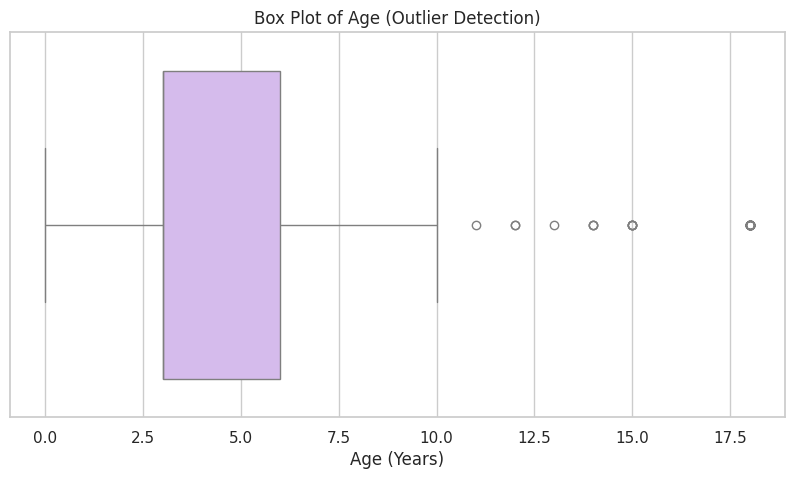

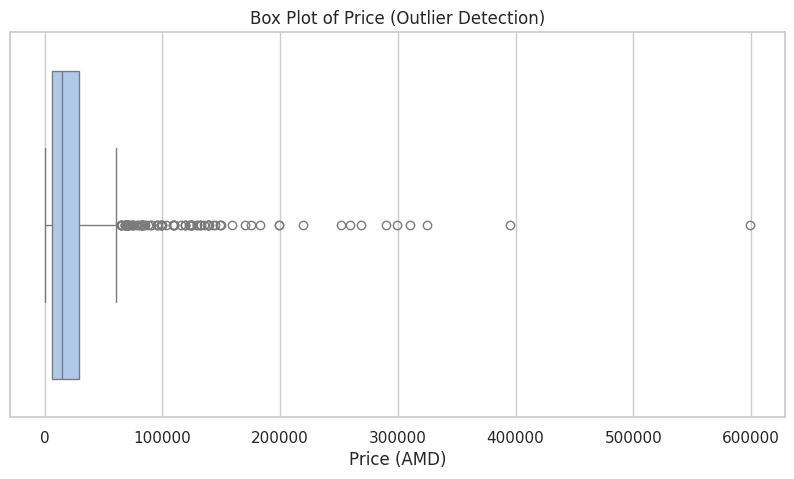

In [ ]:
# 1. BOX PLOT FOR AGE
plt.figure(figsize=FIG_SIZE)

sns.boxplot(
    x=df["Age"],
    color=pastel_purple
)

# Add plot title and axis labels
plt.title("Box Plot of Age (Outlier Detection)")
plt.xlabel("Age (Years)")

# Display the plot
plt.show()



# 2. BOX PLOT FOR PRICE
plt.figure(figsize=FIG_SIZE)

sns.boxplot(
    x=df["Price"],
    color=pastel_blue
)

# Add plot title and axis labels
plt.title("Box Plot of Price (Outlier Detection)")
plt.xlabel("Price (AMD)")

# Display the plot
plt.show()

#### 5.5.2 Results of Scatter Plot Analysis

**The box plot of Age** shows that most toys target children between approximately 3 and 7 years old, while a few products are designed for much older age groups and appear as outliers.

**The box plot of Price** shows that most toys are concentrated in the low-middle price range, while several highly expensive products exist as strong outliers. This indicates a highly right-skewed price distribution with premium products clearly separated from the majority.

## 6. Results Explanation

### 6.1 Interpretation of the Results

This analysis was performed on a dataset of toy products from MegaToys.am, containing information about **Age, Price, Brand, Price Categories, and Encoded Features**. The results provide valuable insights into pricing behavior, brand influence, and target age distribution in the toy market.

### 6.1.1 Descriptive Statistics Interpretation

The age statistics show that:

* The average target age of products is 4.21 years, while the median age is 3 years.
* This indicates that the shop's products are largely focused on toys for toddlers and young children.
* The standard deviation of age (≈3 years) shows moderate variation, but most products are concentrated in the 0–10 years range.

The price statistics show that:

* The mean price is approximately 24,058 AMD, while the median price is 14,900 AMD.
* The mode price is 4,900 AMD, meaning this price appears most frequently.
* This difference between mean and median suggests that a small number of very expensive toys are pushing the average upward.
* The price range is extremely wide: from 400 AMD to 599,000 AMD, indicating the presence of both affordable and luxury or premium products.

#### 6.1.2 Distribution Analysis Results

From the histograms and density plots:

Age Distribution:

* The age distribution is right-skewed.
* Most toys are clustered around ages 2-6, especially around age 3-4.
* Toys for older ages (10+ years) are much less frequent.
* Skewness of Age: 1.93 → Positively skewed
* Kurtosis of Age: 5.78 → Heavy tails

Price Distribution:

* The price distribution is highly right-skewed.
* Most toys are priced in the low price range (below 50,000 AMD).
* There is a long tail of extremely expensive products, confirming the existence of price outliers.
* Skewness of Price: 6.19 → Strongly right-skewed
* Kurtosis of Price: 64.69 → Extremely heavy tails (many extreme outliers)

These results prove that the data is not normally distributed.


#### 6.1.3 Scatter Plot Interpretation

From the scatter plots:

Age vs Price

* There is no strong linear relationship between age and price.
* Toys for almost all ages exist in both low and high price ranges.
* Expensive toys are scattered across different ages, meaning that age does not directly control price.

Age vs Encoded Brand

* Brands are spread across different age groups.
* No strong clustering shows that brands tend to target multiple age groups, rather than specializing only in babies or older children.

Price vs Encoded Brand

* Clear visual clustering based on brand.
* Some brands consistently appear in higher price ranges, while others are clustered in the lower price range. This shows that brand has a stronger influence on price than age.

Age vs Price Category

* Low and Medium price categories exist across almost all ages.
* High price toys appear less frequently and are scattered. This confirms that price category is not rigidly tied to age.

#### 6.1.4 Correlation Heat Map Interpretation

The correlation matrix shows the following relationships:

| Variables            | Correlation|
| ---------------------|------------------------------- |
| Age – Price          | 0.096 → Very weak positive     |
| Age – Brand Encoded  | -0.21 → Weak negative          |
| Price – Brand Encoded| -0.081 → Very weak relationship|

Key conclusions are:

* Age and Price are almost independent
* Brand has more influence on price than age

#### 6.1.5 Bar Plot Results Interpretation

Top Brands by Number of Products:

The most dominant brands are:

* Lego – 238 products
* Papo – 215 products
* Vtech – 105 products
* Zapf-Creation – 92 products
* Janod – 76 products

This shows that a small number of brands dominate the toy market.

#### 6.1.6 Box Plot and Outlier Interpretation

Age Box Plot

* Most ages lie in a normal range.
* Several outliers above 10–18 years, indicating that some toys target much older users.

Price Box Plot

* A very large number of price outliers were detected.
* Many toys are clustered in the low price range, while a few extreme products reach hundreds of thousands of drams. This strongly confirms the presence of premium and luxury products.

#### 6.1.7 Hypothesis Testing Interpretation

Hypothesis 1 (T-Test)

H0: No difference in average price between baby toys and non-baby toys
Result:
* p-value < 0.05
* H0 was rejected

This means:
There is a statistically significant difference in pricing between baby toys and non-baby toys. Baby toys and non-baby toys are priced differently in a meaningful way.

Hypothesis 2 (ANOVA)

H0: Popular brands and other brands have the same average price
Result:

* Most common brand: Lego
* p-value < 0.05
* H0 was rejected

This confirms:
There is a statistically significant difference in prices between brands. Certain brands (like LEGO) tend to follow distinct pricing strategies.

### 6.2 Implications of the Results

These findings have several real-world implications for businesses, consumers and for creating good market strategy.

#### 6.2.1 For Businesses:

* Pricing is more influenced by brand reputation than by the target age of the toy.
* Premium brands can successfully charge higher prices.
* Budget brands can remain competitive in the low-price segment.

#### 6.2.2 For Consumers:

* Parents can find affordable toys for almost all age groups.
* Higher price does not necessarily mean older age suitability.

#### 6.2.3 For Market Strategy:

* Companies can segment the market clearly into budget, mid-range, and premium lines.
* Brand positioning plays a more important role than age targeting.

### 6.3 Potential Applications of the Findings

These results can be applied to:

* Pricing strategy optimization
* Brand positioning analysis
* Market segmentation**
* Recommendation systems for e-commerce platforms
* Stock planning based on demand distribution

# Conclusion
This project successfully collected and analyzed real-world product data from an e-commerce toy store MegaToys.am using automated web scraping and data analysis techniques.

The study showed that:
* Toy prices are highly skewed and dominated by outliers
* Brand is a stronger price driver than age
* Significant statistical differences exist between product groups
* A few brands dominate the market

Overall, this project demonstrates how web scraping combined with exploratory data analysis and statistical testing can provide valuable insights into market behavior and consumer product strategies. The techniques used in this project can be applied to other online markets for business analytics, competitive research, and pricing optimization.